# **1.1 Análisis descriptivo y versionado inicial de datos** 

Aparte de las librerías estándar, cargamos módulos propios con las funciones que definimos nosotros.

Leemos los archivos como un diccionario llamados datos, que a su vez contiene diccionarios con un DataFrame por hoja del archivo original.

El orden en el que leemos los archivos, con el indexado de Python, es el siguiente:

- 0: Totalizadores Planta - 2021_2023.xlsx
- 1: Totalizadores Planta 2020_2022.xlsx
- 2: Totalizadores Planta 2022_2023.xlsx

Dejamos los datos crudos en ``datos_raw`` y trabajamos limpiando su copia en la variable ``datos``.

#### Carga de librerías

In [ ]:
import sys
import copy
import json

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path("..") / "src"))
from eda_1_1_auxiliar import *
from integridad import huella, actualizar_checksums # Genera los hash

#### Verificamos que los datos crudos sean los correctos

In [54]:
carpeta_datos = Path("..") / "data"

guardados = json.load(open(carpeta_datos / "checksums.json"))

estados = []
for archivo in sorted(carpeta_datos.glob("*.xlsx")):
    esperado = guardados.get(archivo.name)
    if esperado is None:
        estados.append((archivo.name, "SIN REGISTRO"))
    else:
        estados.append((archivo.name, "OK" if huella(archivo) == esperado else "DISTINTO"))

for nombre, estado in estados:
    print(f"El archivo {nombre} está {estado:13s}")

assert estados and all(e == "OK" for _, e in estados), "Los datos crudos no coinciden con checksums.json"
print("\nChecksums OK: los datos crudos son los de referencia.")

El archivo Totalizadores Planta - 2021_2023.xlsx está OK           
El archivo Totalizadores Planta 2020_2022.xlsx está OK           
El archivo Totalizadores Planta 2022_2023.xlsx está OK           

Checksums OK: los datos crudos son los de referencia.


#### Carga de datos

In [ ]:
archivos_excel = sorted(carpeta_datos.glob("*.xlsx"))

datos_raw = {}
mapeo_columnas = {}   # (archivo, hoja_snake) -> {columna_original: columna_snake}
mapeo_hojas = {}      # (archivo, hoja_snake) -> nombre_original_de_la_hoja

for i, archivo in enumerate(archivos_excel):
    hojas = pd.read_excel(archivo, sheet_name=None, engine="calamine")
    hojas_snake = {}
    for hoja, df in hojas.items():
        hoja_snake = a_snake_case(hoja)
        # Si dos hojas colapsan al mismo nombre, se avisa en vez de pisar una con otra
        if hoja_snake in hojas_snake:
            raise ValueError(f"Archivo {i}: la hoja '{hoja}' colisiona con otra como '{hoja_snake}'")

        originales = list(df.columns)
        df.columns = snake_case_unicas(originales)

        mapeo_columnas[(i, hoja_snake)] = dict(zip(originales, df.columns))
        mapeo_hojas[(i, hoja_snake)] = hoja
        hojas_snake[hoja_snake] = df
    datos_raw[i] = hojas_snake
    print(f"Leído archivo {i}: {archivo.name}")

datos = copy.deepcopy(datos_raw)

Leído archivo 0: Totalizadores Planta - 2021_2023.xlsx
Leído archivo 1: Totalizadores Planta 2020_2022.xlsx
Leído archivo 2: Totalizadores Planta 2022_2023.xlsx


In [3]:
filas = []
for i, hojas in datos.items():
    for hoja, df in hojas.items():
        df_limpio, reporte = limpiar_numericas(df)
        datos[i][hoja] = df_limpio
        for col, n, ejemplos in reporte:
            filas.append({
                "Archivo": archivos_excel[i].name,
                "Hoja": hoja,
                "Columna": col,
                "Valores convertidos a NaN": n,
                "Ejemplos": ", ".join(ejemplos),
            })

convertidos = pd.DataFrame(filas)
if convertidos.empty:
    print("No se convirtió ningún valor a NaN.")
else:
    display(convertidos.sort_values(["Archivo", "Hoja", "Columna"]).reset_index(drop=True))

,Archivo,Hoja,Columna,Valores convertidos a NaN,Ejemplos
0,Totalizadores Planta 2020_2022.xlsx,totalizadores_produccion,nivel_silo_bagazo_norte_1,1,


## **Unificación de los archivos**

Empezamos examinando los archivos por separado y tratando de que sean lo más consistentes entre sí.

Luego, empezamos por unificar cada archivo en un único DataFrame, uniendo sus hojas.

Finalmente, unificamos los 3 DataFrames.

### **Consistencia entre los archivos**

#### **Hojas de cada archivo**

En el 1er archivo que leímos (que va de 2021 a 2023) tenemos la hoja "Seguimiento día", que en los demás no tenemos.

Mirando la hoja, vemos que no nos aporta mucha información. Tiene muchas columnas vacías y la única información que contiene es si el dato de una hora es el último de su correspondiente día. Como es información que podemos inferir de las otras columnas si es necesario y no es una hoja que tenemos disponible para el resto de los archivos, decidimos quitarla.

In [4]:
nombres = {i: archivos_excel[i].name for i in datos}

# Matriz hoja x archivo: True si la hoja existe en ese archivo
todas_las_hojas = sorted(set().union(*[set(h.keys()) for h in datos.values()]))
presencia = pd.DataFrame(
    {i: [hoja in datos[i] for hoja in todas_las_hojas] for i in datos},
    index=todas_las_hojas,
)
presencia["en_todos"] = presencia.all(axis=1)
print(f"Hojas distintas encontradas: {len(todas_las_hojas)}")
print(f"Hojas por archivo: { {i: len(h) for i, h in datos.items()} }")

# Hojas que no están presentes en todos los archivos
hojas_incompletas = presencia.index[~presencia["en_todos"]].tolist()
print(f"\nHojas que no están en todos los archivos ({len(hojas_incompletas)}):")
for hoja in hojas_incompletas:
    faltan_en = [nombres[i] for i in datos if not presencia.loc[hoja, i]]
    print(f"  - {hoja} | falta en: {faltan_en}")

presencia

Hojas distintas encontradas: 16
Hojas por archivo: {0: 16, 1: 15, 2: 15}

Hojas que no están en todos los archivos (1):
  - seguimiento_dia | falta en: ['Totalizadores Planta 2020_2022.xlsx', 'Totalizadores Planta 2022_2023.xlsx']


,0,1,2,en_todos
auxiliar,True,True,True,True
consolidado_agua,True,True,True,True
consolidado_aire,True,True,True,True
consolidado_ee,True,True,True,True
consolidado_gasvapor,True,True,True,True
consolidado_kpi,True,True,True,True
consolidado_produccion,True,True,True,True
seguimiento_dia,True,False,False,False
totalizadores_agua,True,True,True,True
totalizadores_aire,True,True,True,True


In [5]:
# unnamed_3 es una id de la fila, unnamed_4 parece estar vacía, y ultimo_dato_del_dia es una indicadora
datos[0]["seguimiento_dia"].head(10)

,dia,hora,ultimo_dato_del_dia,unnamed_3,unnamed_4
0,2021-07-01,02:00:00,0,20002,NaN
1,2021-07-01,03:00:00,0,20003,NaN
2,2021-07-01,04:00:00,0,20004,NaN
3,2021-07-01,05:00:01,0,20005,NaN
4,2021-07-01,06:00:01,0,20006,NaN
5,2021-07-01,07:00:00,0,20007,NaN
6,2021-07-01,08:00:00,0,20008,NaN
7,2021-07-01,09:00:01,0,20009,NaN
8,2021-07-01,10:00:00,0,20010,NaN
9,2021-07-01,11:00:00,0,20011,NaN


In [6]:
del datos[0]["seguimiento_dia"]

#### **Columnas en cada hoja**

Nos preguntamos si en las hojas comunes de los archivos tenemos las mismas columnas, y vemos que no.

In [7]:
resumen_cols, diferencias_cols = comparar_columnas(datos, archivos_excel)


[auxiliar] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2022_2023.xlsx:
     Faltan: ['7', '31']
     Sobran: ['unnamed_0', 'unnamed_3', 'hl_linea_2']

[consolidado_agua] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2020_2022.xlsx:
     Faltan: ['agua_paste_l3', 'agua_lavadora_l3', 'agua_cond_evaporativos', 'agua_calderas', 'agua_efluentes', 'agua_co2']
     Sobran: []

[consolidado_gasvapor] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2020_2022.xlsx:
     Faltan: ['vapor_l5_kg', 'tot_vap_paste_l3_hora', 'tot_vap_lav_l3_hora', 'medicion_gas_planta_m3']
     Sobran: ['vapor_vapor_l5_kg']

[consolidado_kpi] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2020_2022.xlsx:
     Faltan: ['aire_expulsion_hl', 'co_2_linea_2_hl', 'agua_lavadora_l3_hl', 'agua_paste_l3_hl', 'unnamed_65', 'unnamed_66', 'unnamed_67', 'meta_ee_planta', 'me

,Hoja,Columnas por archivo,Mismas columnas,Mismo orden,Archivos distintos
0,auxiliar,"[34, 34, 35]",False,False,[Totalizadores Planta 2022_2023.xlsx]
1,consolidado_agua,"[24, 18, 24]",False,False,[Totalizadores Planta 2020_2022.xlsx]
2,consolidado_aire,"[14, 14, 14]",True,True,[]
3,consolidado_ee,"[21, 21, 21]",True,True,[]
4,consolidado_gasvapor,"[20, 17, 20]",False,False,[Totalizadores Planta 2020_2022.xlsx]
5,consolidado_kpi,"[123, 62, 125]",False,False,"[Totalizadores Planta 2020_2022.xlsx, Totaliza..."
6,consolidado_produccion,"[13, 12, 18]",False,False,"[Totalizadores Planta 2020_2022.xlsx, Totaliza..."
7,totalizadores_agua,"[43, 43, 44]",False,False,[Totalizadores Planta 2022_2023.xlsx]
8,totalizadores_aire,"[11, 11, 12]",False,False,[Totalizadores Planta 2022_2023.xlsx]
9,totalizadores_co2,"[8, 8, 9]",False,False,[Totalizadores Planta 2022_2023.xlsx]


#### **Columnas poco informativas**

Queremos eliminar la mayor cantidad de columnas que no aporten información de relevancia a nuestro problema. Para ello:

- Las columnas "sin_nombre_nro" y "unnamed_nro" tienen gran porcentaje de datos faltantes (>90%). Eliminamos las que cumplen con esta condición.

- Las columnas de tipo "meta_" tienen muy poca variabilidad, así que las eliminamos.

- Las columnas de tipo "id" son enumeraciones de las filas, así que las eliminamos.

- Eliminamos las columnas que tengan más de $80\%$ de datos faltantes.

- Eliminamos las columnas con nombres numéricos (por ejemplo: "31"), que mayormente tienen alto porcentaje de datos faltantes o muy pocos valores únicos.

In [8]:
PATRONES = {
    "sin nombre": r"unnamed|sin_nombre",
    "meta":       r"(^|_)metas?(_|$)",   # 'meta' como palabra completa entre guiones bajos
    "numéricas":  r"^\d+(_\d+)*$",       # nombres que son un número: "2", "15", "1_0"
}

In [9]:
tabla = resumen_columnas_patron(datos, archivos_excel, PATRONES["sin nombre"], mostrar = False)
eliminadas_unnamed = eliminar_columnas(datos, archivos_excel, tabla, aplicar = True)    

Columnas eliminadas: 42


,Archivo,Hoja,Columna,% datos faltantes,Valores únicos,Desvío estándar,Motivo
0,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,unnamed_103,100.00,0,NaN,faltantes > 90%
1,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,unnamed_113,100.00,0,NaN,faltantes > 90%
2,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,unnamed_21,100.00,0,NaN,faltantes > 90%
3,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,unnamed_22,100.00,0,NaN,faltantes > 90%
4,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,unnamed_35,100.00,0,NaN,faltantes > 90%
5,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,unnamed_46,100.00,0,NaN,faltantes > 90%
6,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,unnamed_65,100.00,0,NaN,faltantes > 90%
7,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,unnamed_66,100.00,0,NaN,faltantes > 90%
8,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,unnamed_67,100.00,0,NaN,faltantes > 90%
9,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,unnamed_72,100.00,0,NaN,faltantes > 90%


In [10]:
tabla = resumen_columnas_patron(datos, archivos_excel, PATRONES["meta"], mostrar = False)
eliminadas_meta = eliminar_columnas(datos, archivos_excel, tabla, min_desvio=10, aplicar = True)

Columnas eliminadas: 102


,Archivo,Hoja,Columna,% datos faltantes,Valores únicos,Desvío estándar,Motivo
0,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,meta_agua_bodega,0.01,10,0.048634,desvío < 10
1,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,meta_agua_cocina,0.01,9,0.085110,desvío < 10
2,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,meta_agua_elab,0.01,10,0.111251,desvío < 10
3,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,meta_agua_envas,0.01,10,0.065656,desvío < 10
4,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,meta_agua_linea_2,0.01,9,0.127665,desvío < 10
...,...,...,...,...,...,...,...
97,Totalizadores Planta 2022_2023.xlsx,consolidado_kpi,meta_et_linea_4,0.01,15,0.762014,desvío < 10
98,Totalizadores Planta 2022_2023.xlsx,consolidado_kpi,meta_et_linea_5,0.01,15,1.172329,desvío < 10
99,Totalizadores Planta 2022_2023.xlsx,consolidado_kpi,meta_et_planta,0.01,14,7.737374,desvío < 10
100,Totalizadores Planta 2022_2023.xlsx,consolidado_kpi,meta_et_servicios,0.01,15,0.457208,desvío < 10


In [11]:
tabla = resumen_columnas_patron(datos, archivos_excel, PATRONES["numéricas"], mostrar = False)
eliminadas_num = eliminar_columnas(datos, archivos_excel, tabla, aplicar = True)

Columnas eliminadas: 88


,Archivo,Hoja,Columna,% datos faltantes,Valores únicos,Desvío estándar,Motivo
0,Totalizadores Planta - 2021_2023.xlsx,auxiliar,10,100.00,0,NaN,faltantes > 90%
1,Totalizadores Planta - 2021_2023.xlsx,auxiliar,11,100.00,0,NaN,faltantes > 90%
2,Totalizadores Planta - 2021_2023.xlsx,auxiliar,12,100.00,0,NaN,faltantes > 90%
3,Totalizadores Planta - 2021_2023.xlsx,auxiliar,13,100.00,0,NaN,faltantes > 90%
4,Totalizadores Planta - 2021_2023.xlsx,auxiliar,14,100.00,0,NaN,faltantes > 90%
...,...,...,...,...,...,...,...
83,Totalizadores Planta 2020_2022.xlsx,auxiliar,5,1.14,2,0.206197,desvío < 10
84,Totalizadores Planta 2022_2023.xlsx,auxiliar,5,0.01,1,0.000000,desvío < 10
85,Totalizadores Planta - 2021_2023.xlsx,auxiliar,2,0.00,2,0.191868,desvío < 10
86,Totalizadores Planta 2020_2022.xlsx,auxiliar,2,0.00,2,0.149231,desvío < 10


In [12]:
eliminadas_id = eliminar_por_nombre(datos, archivos_excel, r"id", aplicar=True)

Columnas eliminadas: 9


,Archivo,Hoja,Columna
0,Totalizadores Planta 2020_2022.xlsx,totalizadores_glicol,id
1,Totalizadores Planta 2022_2023.xlsx,totalizadores_produccion,id
2,Totalizadores Planta 2022_2023.xlsx,totalizadores_energia,id
3,Totalizadores Planta 2022_2023.xlsx,totalizadores_agua,id
4,Totalizadores Planta 2022_2023.xlsx,totalizadores_gas_y_vapor,id
5,Totalizadores Planta 2022_2023.xlsx,totalizadores_aire,id
6,Totalizadores Planta 2022_2023.xlsx,totalizadores_co2,id
7,Totalizadores Planta 2022_2023.xlsx,totalizadores_efluentes,id
8,Totalizadores Planta 2022_2023.xlsx,totalizadores_glicol,id


In [13]:
tabla = resumen_columnas_patron(datos, archivos_excel, "", min_faltantes=80, mostrar=False)
eliminadas_faltantes = eliminar_columnas(datos, archivos_excel, tabla, max_faltantes=80, aplicar = True)

Columnas eliminadas: 4


,Archivo,Hoja,Columna,% datos faltantes,Valores únicos,Desvío estándar,Motivo
0,Totalizadores Planta - 2021_2023.xlsx,consolidado_kpi,ee_linea_5_hl,100.0,0,NaN,faltantes > 80%
1,Totalizadores Planta 2020_2022.xlsx,consolidado_kpi,ee_linea_5_hl,100.0,0,NaN,faltantes > 80%
2,Totalizadores Planta 2020_2022.xlsx,totalizadores_glicol,tot_a10_20,100.0,0,NaN,faltantes > 80%
3,Totalizadores Planta 2022_2023.xlsx,consolidado_kpi,ee_linea_5_hl,100.0,0,NaN,faltantes > 80%


#### **Inconsistencias**

Tras las eliminaciones del paso anterior, las discrepancias disminuyeron, pero no desaparecieron por completo. Revisamos las columnas que siguen sin estar presentes en todas las hojas.

In [14]:
resumen_cols, diferencias_cols = comparar_columnas(datos, archivos_excel)


[auxiliar] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2022_2023.xlsx:
     Faltan: []
     Sobran: ['hl_linea_2']

[consolidado_agua] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2020_2022.xlsx:
     Faltan: ['agua_paste_l3', 'agua_lavadora_l3', 'agua_cond_evaporativos', 'agua_calderas', 'agua_efluentes', 'agua_co2']
     Sobran: []

[consolidado_gasvapor] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2020_2022.xlsx:
     Faltan: ['vapor_l5_kg', 'tot_vap_paste_l3_hora', 'tot_vap_lav_l3_hora', 'medicion_gas_planta_m3']
     Sobran: ['vapor_vapor_l5_kg']

[consolidado_kpi] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2020_2022.xlsx:
     Faltan: ['aire_expulsion_hl', 'co_2_linea_2_hl', 'agua_lavadora_l3_hl', 'agua_paste_l3_hl']
     Sobran: []

[consolidado_produccion] Diferencias respecto de Totalizadores Planta - 2021_2023

,Hoja,Columnas por archivo,Mismas columnas,Mismo orden,Archivos distintos
0,auxiliar,"[4, 4, 5]",False,False,[Totalizadores Planta 2022_2023.xlsx]
1,consolidado_agua,"[24, 18, 24]",False,False,[Totalizadores Planta 2020_2022.xlsx]
2,consolidado_aire,"[14, 14, 14]",True,True,[]
3,consolidado_ee,"[21, 21, 21]",True,True,[]
4,consolidado_gasvapor,"[20, 17, 20]",False,False,[Totalizadores Planta 2020_2022.xlsx]
5,consolidado_kpi,"[60, 56, 60]",False,False,[Totalizadores Planta 2020_2022.xlsx]
6,consolidado_produccion,"[13, 12, 13]",False,False,[Totalizadores Planta 2020_2022.xlsx]
7,totalizadores_agua,"[43, 43, 43]",True,True,[]
8,totalizadores_aire,"[11, 11, 11]",True,True,[]
9,totalizadores_co2,"[8, 8, 8]",True,True,[]


- En las hojas "consolidado_produccion" de los archivos 2021-2023 y 2022-2023 existe una columna ``hl_de_mosto_copia``, que eliminamos por ser idéntica a ``hl_de_mosto``.

In [15]:
# df1.equals(df2) devuelve True si los dataframes son iguales
print(datos[0]["consolidado_produccion"]["hl_de_mosto"].equals(datos[0]["consolidado_produccion"]["hl_de_mosto_copia"]))
print(datos[2]["consolidado_produccion"]["hl_de_mosto"].equals(datos[2]["consolidado_produccion"]["hl_de_mosto_copia"]))

datos[0]["consolidado_produccion"].drop(columns='hl_de_mosto_copia', inplace=True)
datos[2]["consolidado_produccion"].drop(columns='hl_de_mosto_copia', inplace=True)

True
True


- En el archivo "Totalizadores Planta 2022_2023.xlsx", en hoja "totalizadores_produccion", falta la columna "hl_reserva_7".
    Como en los otros archivos dicha columna no contiene información relevante, podemos eliminarla de todas.

- En el mismo archivo y hoja se encuentra la columna "hl_session_ipa", que no está en los otros. Por lo tanto, podemos eliminarla.

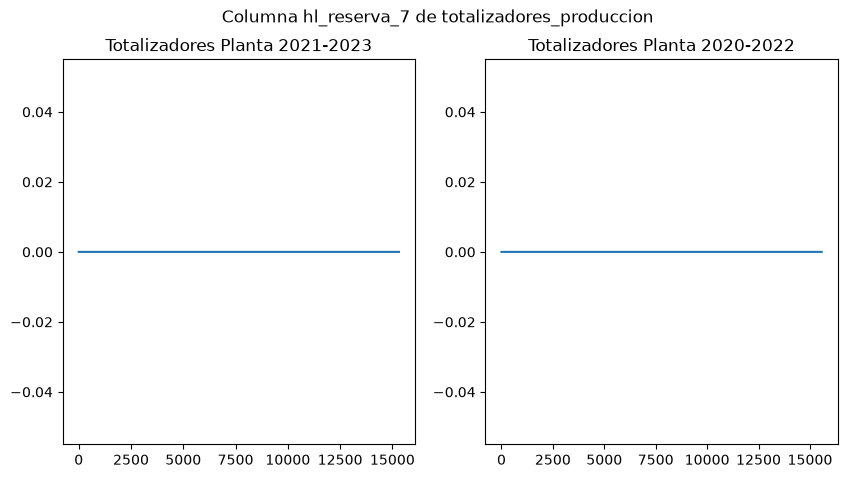

In [16]:
plt.figure(figsize=(10, 5))
plt.suptitle("Columna hl_reserva_7 de totalizadores_produccion")
plt.subplot(1, 2, 1)
plt.title("Totalizadores Planta 2021-2023")
plt.plot(datos[0]["totalizadores_produccion"]["hl_reserva_7"])
plt.subplot(1, 2, 2)
plt.title("Totalizadores Planta 2020-2022")
plt.plot(datos[1]["totalizadores_produccion"]["hl_reserva_7"]);


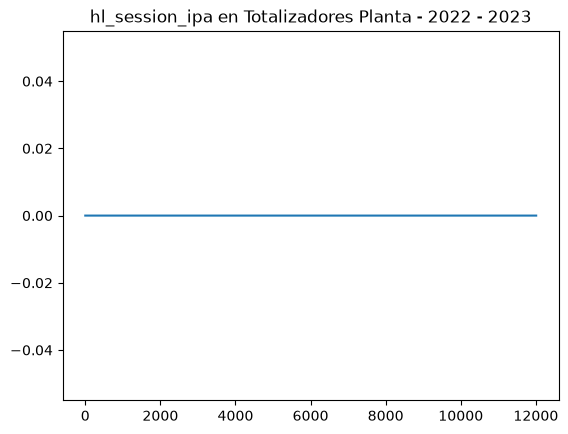

In [17]:
plt.figure()
plt.title("hl_session_ipa en Totalizadores Planta - 2022 - 2023")
plt.plot(datos[2]["totalizadores_produccion"]["hl_session_ipa"]);

In [18]:
datos[0]["totalizadores_produccion"].drop(columns='hl_reserva_7', inplace=True)
datos[1]["totalizadores_produccion"].drop(columns='hl_reserva_7', inplace=True)
datos[2]["totalizadores_produccion"].drop(columns='hl_session_ipa', inplace=True)

#### **Otros cambios**

Renombramos columnas que contienen errores de tipeo.
        
- En el archivo 2020-2022, hoja "consolidado_gasvapor", renombramos "vapor_vapor_l5_kg" a "vapor_l5_kg".

- En el archivo 2020-2022, hoja "totalizadores_gas_y_vapor", renombramos "vapor_vapor_l5_kg" a "vapor_l5_kg".

- En el archivo 2020-2022, hoja "totalizadores_glicol", renombramos "tot_fermantacion_cocina" a "tot_fermentacion_cocina".

In [19]:
datos[1]["consolidado_gasvapor"].rename(columns = {"vapor_vapor_l5_kg" : "vapor_l5_kg"}, inplace = True)
datos[1]["totalizadores_gas_y_vapor"].rename(columns = {"vapor_vapor_l5_kg" : "vapor_l5_kg"}, inplace = True)
datos[1]["totalizadores_glicol"].rename(columns = {"tot_fermantacion_cocina" : "tot_fermentacion_cocina"}, inplace = True)

Al examinar la hoja "auxiliar", vemos que no contiene información de relevante. La eliminamos de todos los archivos.

In [20]:
datos[0]["auxiliar"].head(10)

,dia,hora,sin_nombre,1
0,2021-07-01,02:00:00,445620,445620.083333
1,2021-07-01,03:00:00,445620,445620.125000
2,2021-07-01,04:00:00,445620,445620.166667
3,2021-07-01,05:00:01,445620,445620.208345
4,2021-07-01,06:00:01,445620,445620.250012
5,2021-07-01,07:00:00,445620,445620.291667
6,2021-07-01,08:00:00,445620,445620.333333
7,2021-07-01,09:00:01,445620,445620.375012
8,2021-07-01,10:00:00,445620,445620.416667
9,2021-07-01,11:00:00,445620,445620.458333


In [21]:
datos[1]["auxiliar"].head(10)

,dia,hora,sin_nombre,1
0,2020-07-01,00:00:00,441970,441970.000000
1,2020-07-01,01:00:00,441970,441970.041667
2,2020-07-01,02:00:00,441970,441970.083333
3,2020-07-01,03:00:00,441970,441970.125000
4,2020-07-01,04:00:00,441970,441970.166667
5,2020-07-01,05:00:00,441970,441970.208333
6,2020-07-01,06:00:00,441970,441970.250000
7,2020-07-01,07:00:00,441970,441970.291667
8,2020-07-01,08:00:00,441970,441970.333333
9,2020-07-01,09:00:00,441970,441970.375000


In [22]:
datos[2]["auxiliar"].head(10)

,dia,hora,sin_nombre,1,hl_linea_2
0,2022-07-01,00:00:00,449270,449270.000000,0.0
1,2022-07-01,01:00:00,449270,449270.041667,0.0
2,2022-07-01,02:00:00,449270,449270.083333,0.0
3,2022-07-01,03:00:00,449270,449270.125000,0.0
4,2022-07-01,04:00:01,449270,449270.166678,0.0
5,2022-07-01,05:00:00,449270,449270.208333,0.0
6,2022-07-01,06:00:00,449270,449270.250000,0.0
7,2022-07-01,07:00:00,449270,449270.291667,0.0
8,2022-07-01,08:00:00,449270,449270.333333,0.0
9,2022-07-01,09:00:00,449270,449270.375000,0.0


In [23]:
del datos[0]["auxiliar"]
del datos[1]["auxiliar"]
del datos[2]["auxiliar"]


#### **Última revisión**

Revisamos manualmente las discrepancias que persisten entre distintos archivos observando las columnas que faltan o sobran y resolvemos no hacer modificaciones por considerar que contienen información relevante.

In [24]:
resumen_cols, diferencias_cols = comparar_columnas(datos, archivos_excel)


[consolidado_agua] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2020_2022.xlsx:
     Faltan: ['agua_paste_l3', 'agua_lavadora_l3', 'agua_cond_evaporativos', 'agua_calderas', 'agua_efluentes', 'agua_co2']
     Sobran: []

[consolidado_gasvapor] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2020_2022.xlsx:
     Faltan: ['tot_vap_paste_l3_hora', 'tot_vap_lav_l3_hora', 'medicion_gas_planta_m3']
     Sobran: []

[consolidado_kpi] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2020_2022.xlsx:
     Faltan: ['aire_expulsion_hl', 'co_2_linea_2_hl', 'agua_lavadora_l3_hl', 'agua_paste_l3_hl']
     Sobran: []

[totalizadores_gas_y_vapor] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totalizadores Planta 2020_2022.xlsx:
     Faltan: ['vapor_paste_l3']
     Sobran: []

[totalizadores_glicol] Diferencias respecto de Totalizadores Planta - 2021_2023.xlsx:
  Totali

,Hoja,Columnas por archivo,Mismas columnas,Mismo orden,Archivos distintos
0,consolidado_agua,"[24, 18, 24]",False,False,[Totalizadores Planta 2020_2022.xlsx]
1,consolidado_aire,"[14, 14, 14]",True,True,[]
2,consolidado_ee,"[21, 21, 21]",True,True,[]
3,consolidado_gasvapor,"[20, 17, 20]",False,False,[Totalizadores Planta 2020_2022.xlsx]
4,consolidado_kpi,"[60, 56, 60]",False,False,[Totalizadores Planta 2020_2022.xlsx]
5,consolidado_produccion,"[12, 12, 12]",True,True,[]
6,totalizadores_agua,"[43, 43, 43]",True,True,[]
7,totalizadores_aire,"[11, 11, 11]",True,True,[]
8,totalizadores_co2,"[8, 8, 8]",True,True,[]
9,totalizadores_efluentes,"[8, 8, 8]",True,True,[]


### **Unificación de cada archivo en un DataFrame**

#### **Días en los que no se reinició el contador**

Queremos detectar los casos en los que no se reinició el contador. Para detectarlos, buscamos en qué fechas el registro de las $00:00$ no es nulo, con algunas sutilezas que descubrimos analizando los datos:

- Hay columnas en totalizadores_produccion y en totalizadores_agua que no representan cantidades que aumentan sino niveles de almacenamiento (`nivel_silo_bagazo_norte_1`, por ejemplo) o temperaturas (`temp_tq_intermedio`), que no necesariamente deben reiniciarse cada día.

- Hay columnas que se resetean después de las $00:00$, o cuyo valor a las $00:00$ es el de las $23:59$ del día anterior pero que luego continúan con el conteo adecuadamente. 

Como vamos a quedarnos solo con los datos de las $23:59$, estos casos no nos afectan. Los que si nos preocupan son aquellos en los que genuinamente un acumulador diario no se reinició. Para ello, vamos a buscar los días en los que el primer registro del día no es nulo y además los registros de ese día son **estrictamente crecientes** (si no lo son, probablemente estemos en un caso de los descritos previamente, que no resultan problemáticos).

In [25]:
# Ejemplos 
display(datos[0]["totalizadores_produccion"][25:50][["dia", "hora", "nivel_silo_bagazo_norte_1"]].T)
display(datos[0]["totalizadores_agua"][:25][["dia", "hora", "temp_tq_intermedio"]].T)

,25,26,27,28,29,30,31,32,33,34,...,40,41,42,43,44,45,46,47,48,49
dia,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,...,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00,2021-07-03 00:00:00,2021-07-03 00:00:00
hora,02:00:00,03:00:00,04:00:00,05:00:00,06:00:01,07:00:00,08:00:01,09:00:01,10:00:01,11:00:00,...,17:00:00,18:00:00,19:00:00,20:00:01,21:00:00,22:00:00,23:00:00,23:59:00,00:00:00,01:00:01
nivel_silo_bagazo_norte_1,48.35,48.38,48.44,8.16,8.43,0.0,0.0,0.0,2.49,0.0,...,0.0,0.01,1.17,0.01,1.49,2.78,0.0,0.0,0.0,0.0


,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
dia,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,...,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-01 00:00:00,2021-07-02 00:00:00,2021-07-02 00:00:00
hora,02:00:00,03:00:00,04:00:00,05:00:01,06:00:01,07:00:00,08:00:00,09:00:01,10:00:00,11:00:00,...,17:00:00,18:00:00,19:00:00,20:00:00,21:00:00,22:00:00,23:00:00,23:59:00,00:00:00,01:00:00
temp_tq_intermedio,23.22,23.05,22.96,22.73,22.48,22.73,22.53,23.09,23.63,23.63,...,22.5,22.42,22.19,22.27,22.31,23.12,22.37,22.71,22.71,22.42


Al analizar los casos problemáticos, notamos lo siguiente: 

- En el caso con mayor diferencia relativa entre el último valor del día anterior y el primer valor del día que no se reinició, la columna es una de las que descartamos que deban reiniciarse (``nivel_silo_bagazo_norte_1``).

- En el 2do caso con mayor diferencia relativa, que además es nuestra variablerespuesta, esta diferencia probablemente no se debe a que el 1er valor no es nulo, ya que este es muy pequeño a comparación de la diferencia. Por lo tanto, no es necesario hacer un cambio.

- En los otros casos, o bien la diferencia es pequeña, o bien no parece ser por causa de un acumulador no reiniciado (como en el caso de las variables con diferencia relativa negativa).

Por todo esto, concluimos que o bien no hay casos de acumuladores que realmente no se resetearon, o bien los mismos no tienen gran impacto en los números finales. Por lo tanto, no realizamos cambios al dataset.

In [26]:
resumen_sr, detalle_sr = acumuladores_sin_reiniciar(datos, archivos_excel, mostrar = False)
display(detalle_sr.sort_values("Diferencia relativa (%)", ascending=False).round({"Diferencia relativa (%)": 1}).reset_index(drop=True))

,Archivo,Hoja,Columna,Día,Hora del primer registro,Primer valor,Último valor del día,Registros con valor,Último valor del día anterior,Diferencia relativa (%)
0,Totalizadores Planta - 2021_2023.xlsx,totalizadores_produccion,nivel_silo_bagazo_norte_1,2021-09-19,0 days,37.3,90.64,25,36.66,147.2
1,Totalizadores Planta 2020_2022.xlsx,totalizadores_produccion,nivel_silo_bagazo_norte_1,2021-09-19,0 days,37.3,90.64,25,36.66,147.2
2,Totalizadores Planta 2020_2022.xlsx,consolidado_ee,frio_kw,2022-02-05,0 days,7.0,20203.00,25,17094.00,18.2
3,Totalizadores Planta - 2021_2023.xlsx,consolidado_ee,frio_kw,2022-02-05,0 days,7.0,20203.00,25,17094.00,18.2
4,Totalizadores Planta 2020_2022.xlsx,totalizadores_energia,kw_secador_kaeser,2022-02-05,0 days,1.0,294.00,25,257.00,14.4
5,Totalizadores Planta - 2021_2023.xlsx,totalizadores_energia,kw_secador_kaeser,2022-02-05,0 days,1.0,294.00,25,257.00,14.4
6,Totalizadores Planta - 2021_2023.xlsx,consolidado_ee,sala_maq_kw,2022-02-05,0 days,11.0,22021.00,25,19360.00,13.7
7,Totalizadores Planta 2020_2022.xlsx,consolidado_ee,sala_maq_kw,2022-02-05,0 days,11.0,22021.00,25,19360.00,13.7
8,Totalizadores Planta 2020_2022.xlsx,consolidado_ee,aire_kw,2020-07-11,0 days,289.0,7618.00,25,6901.00,10.4
9,Totalizadores Planta - 2021_2023.xlsx,consolidado_ee,servicios_kw,2022-02-05,0 days,-11.0,36521.00,25,33721.00,8.3


#### **Días pisados**

Empezamos analizando si en los archivos hay días con más de 25 filas, asumiendo que lo "normal" es que tengan observaciones de a una hora entre las 00:00 y las 23 (24 filas), y una observación a las 23:59. Lo que vemos es que en todas las hojas y archivos hay entre 5 y 10 días con más de 25 filas, es decir, con días "pisados".

Cuando revisamos cuáles son estos días, vemos que son, en general, los días 30 de cada mes, que tienen el doble de filas de las esperadas, y el 28 de febrero, que tiene cuatro veces la cantidad de filas esperadas. 

Por otro lado, en los archivos faltan fechas dentro del rango temporal que abarcan. Las mismas siempre son el 29 y 30 de agosto, y el 31 de los meses que poseen este día. Esto nos indica que los días con más datos de los que deberían tener probablemente contengan información de estos días faltantes.

Para saber a qué fecha asignarle en verdad los datos que "sobran" a cada día, notemos que sólo en el archivo de 2021-2023 sucede que:

- el 30/04 y el 30/06 tienen ambos información sobre otro día
- faltan datos del 31/03 y el 31/05

A partir de esta información, la mejor suposición que podemos hacer sobre los datos es que los datos de los 31 de un mes se guardan en el día 30 del mes siguiente, y los datos del 29 y el 30 de agosto se guardan en el 28 de febrero, por alguna razón.

##### Días con más de 25 registros

In [27]:
detalle_dias, resumen_dias = filas_por_dia(datos, archivos_excel)

,Archivo,Días con 25 filas,Días con más de 25,Máximo de filas por día,Fechas con más de 25
0,Totalizadores Planta - 2021_2023.xlsx,586,8,100,"30/09/2021 (50), 30/11/2021 (50), 28/02/2022 (..."
1,Totalizadores Planta 2020_2022.xlsx,596,8,100,"30/09/2020 (50), 30/11/2020 (50), 28/02/2021 (..."
2,Totalizadores Planta 2022_2023.xlsx,463,6,100,"30/09/2022 (50), 30/11/2022 (50), 28/02/2023 (..."


##### Fechas con más de 25 registros

In [28]:
filas_extra = dias_con_muchas_filas(datos, archivos_excel, "consolidado_agua")

,Totalizadores Planta - 2021_2023,Totalizadores Planta 2020_2022,Totalizadores Planta 2022_2023
Fecha,,,
2020-09-30,<NA>,50,<NA>
2020-11-30,<NA>,50,<NA>
2021-02-28,<NA>,100,<NA>
2021-04-30,<NA>,50,<NA>
2021-06-30,<NA>,51,<NA>
2021-09-30,50,50,<NA>
2021-11-30,50,50,<NA>
2022-02-28,100,100,<NA>
2022-04-30,50,<NA>,<NA>


##### Fechas faltantes en cada archivo

In [29]:
faltantes = fechas_faltantes(datos, archivos_excel)


,Totalizadores Planta - 2021_2023,Totalizadores Planta 2020_2022,Totalizadores Planta 2022_2023,Estado
Fecha,,,,
29/08/2020,—,Falta,—,Falta en todos los que la cubren
30/08/2020,—,Falta,—,Falta en todos los que la cubren
31/08/2020,—,Falta,—,Falta en todos los que la cubren
31/10/2020,—,Falta,—,Falta en todos los que la cubren
31/12/2020,—,Falta,—,Falta en todos los que la cubren
31/03/2021,—,Falta,—,Falta en todos los que la cubren
31/05/2021,—,Falta,—,Falta en todos los que la cubren
29/08/2021,Falta,Falta,—,Falta en todos los que la cubren
30/08/2021,Falta,Falta,—,Falta en todos los que la cubren


##### Reasignamos fechas

In [30]:
# ------------ ARCHIVO 0 (2021 - 2023)
# Movemos 30/MM a 31/MM-1
mover_bloque(datos, archivos_excel, i=0, fecha_origen="2021-09-30", bloque=2, fecha_destino="2021-08-31", aplicar=True)
mover_bloque(datos, archivos_excel, i=0, fecha_origen="2021-11-30", bloque=2, fecha_destino="2021-10-31", aplicar=True)

mover_bloque(datos, archivos_excel, i=0, fecha_origen="2022-04-30", bloque=2, fecha_destino="2022-03-31", aplicar=True) 
mover_bloque(datos, archivos_excel, i=0, fecha_origen="2022-06-30", bloque=2, fecha_destino="2022-05-31", aplicar=True)
mover_bloque(datos, archivos_excel, i=0, fecha_origen="2022-09-30", bloque=2, fecha_destino="2022-08-31", aplicar=True)
mover_bloque(datos, archivos_excel, i=0, fecha_origen="2022-11-30", bloque=2, fecha_destino="2022-10-31", aplicar=True)

# Movemos de 28/02 a 31/12 ???, 29/08 y 30/08
mover_bloque(datos, archivos_excel, i=0, fecha_origen="2022-02-28", bloque=4, fecha_destino="2021-08-29", aplicar=True)
mover_bloque(datos, archivos_excel, i=0, fecha_origen="2022-02-28", bloque=3, fecha_destino="2021-08-30", aplicar=True)
mover_bloque(datos, archivos_excel, i=0, fecha_origen="2022-02-28", bloque=2, fecha_destino="2021-12-31", aplicar=True)

mover_bloque(datos, archivos_excel, i=0, fecha_origen="2023-02-28", bloque=4, fecha_destino="2022-08-29", aplicar=True) 
mover_bloque(datos, archivos_excel, i=0, fecha_origen="2023-02-28", bloque=3, fecha_destino="2022-08-30", aplicar=True)
mover_bloque(datos, archivos_excel, i=0, fecha_origen="2023-02-28", bloque=2, fecha_destino="2022-12-31", aplicar=True)

print()

# ------------ ARCHIVO 1 (2020 - 2022)

# Movemos 30/MM a 31/MM-1
mover_bloque(datos, archivos_excel, i=1, fecha_origen="2020-09-30", bloque=2, fecha_destino="2020-08-31", aplicar=True)
mover_bloque(datos, archivos_excel, i=1, fecha_origen="2020-11-30", bloque=2, fecha_destino="2020-10-31", aplicar=True)

mover_bloque(datos, archivos_excel, i=1, fecha_origen="2021-04-30", bloque=2, fecha_destino="2021-03-31", aplicar=True)
mover_bloque(datos, archivos_excel, i=1, fecha_origen="2021-06-30", bloque=2, fecha_destino="2021-05-31", aplicar=True)
mover_bloque(datos, archivos_excel, i=1, fecha_origen="2021-09-30", bloque=2, fecha_destino="2021-08-31", aplicar=True)
mover_bloque(datos, archivos_excel, i=1, fecha_origen="2021-11-30", bloque=2, fecha_destino="2021-10-31", aplicar=True)

# Movemos de 28/02 a 31/12 ???, 29/08 y 30/08
mover_bloque(datos, archivos_excel, i=1, fecha_origen="2021-02-28", bloque=4, fecha_destino="2020-08-29", aplicar=True)
mover_bloque(datos, archivos_excel, i=1, fecha_origen="2021-02-28", bloque=3, fecha_destino="2020-08-30", aplicar=True)
mover_bloque(datos, archivos_excel, i=1, fecha_origen="2021-02-28", bloque=2, fecha_destino="2020-12-31", aplicar=True)

mover_bloque(datos, archivos_excel, i=1, fecha_origen="2022-02-28", bloque=4, fecha_destino="2021-08-29", aplicar=True)
mover_bloque(datos, archivos_excel, i=1, fecha_origen="2022-02-28", bloque=3, fecha_destino="2021-08-30", aplicar=True)
mover_bloque(datos, archivos_excel, i=1, fecha_origen="2022-02-28", bloque=2, fecha_destino="2021-12-31", aplicar=True)

print() 
# ------------ ARCHIVO 2
# Movemos 30/MM a 31/MM-1
mover_bloque(datos, archivos_excel, i=2, fecha_origen="2022-09-30", bloque=2, fecha_destino="2022-08-31", aplicar=True)
mover_bloque(datos, archivos_excel, i=2, fecha_origen="2022-11-30", bloque=2, fecha_destino="2022-10-31", aplicar=True)

mover_bloque(datos, archivos_excel, i=2, fecha_origen="2023-04-30", bloque=2, fecha_destino="2023-03-31", aplicar=True)
mover_bloque(datos, archivos_excel, i=2, fecha_origen="2023-06-30", bloque=2, fecha_destino="2023-05-31", aplicar=True)
mover_bloque(datos, archivos_excel, i=2, fecha_origen="2023-09-30", bloque=2, fecha_destino="2023-08-31", aplicar=True)

mover_bloque(datos, archivos_excel, i=2, fecha_origen="2023-02-28", bloque=4, fecha_destino="2022-08-29", aplicar=True)
mover_bloque(datos, archivos_excel, i=2, fecha_origen="2023-02-28", bloque=3, fecha_destino="2022-08-30", aplicar=True)
mover_bloque(datos, archivos_excel, i=2, fecha_origen="2023-02-28", bloque=2, fecha_destino="2022-12-31", aplicar=True)

Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 2 de 30/09/2021 → 31/08/2021
Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 2 de 30/11/2021 → 31/10/2021
Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 2 de 30/04/2022 → 31/03/2022
Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 2 de 30/06/2022 → 31/05/2022
Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 2 de 30/09/2022 → 31/08/2022
Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 2 de 30/11/2022 → 31/10/2022
Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 4 de 28/02/2022 → 29/08/2021
Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 3 de 28/02/2022 → 30/08/2021
Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 2 de 28/02/2022 → 31/12/2021
Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 4 de 28/02/2023 → 29/08/2022
Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 3 de 28/02/2023 → 30/08/2022
Archivo: Totalizadores Planta - 2021_2023.xlsx | bloque 2 de 28/0

,Hoja,Bloques en la fecha,Filas del bloque,Hora inicial,Hora final,Filas que ya tiene el destino,Resultado
0,consolidado_kpi,2,25,00:00:00,23:59:00,0,movido
1,consolidado_produccion,2,25,00:00:00,23:59:00,0,movido
2,totalizadores_produccion,2,25,00:00:00,23:59:00,0,movido
3,consolidado_ee,2,25,00:00:00,23:59:00,0,movido
4,totalizadores_energia,2,25,00:00:00,23:59:00,0,movido
5,consolidado_agua,2,25,00:00:00,23:59:00,0,movido
6,totalizadores_agua,2,25,00:00:00,23:59:00,0,movido
7,consolidado_gasvapor,2,25,00:00:00,23:59:00,0,movido
8,totalizadores_gas_y_vapor,2,25,00:00:00,23:59:00,0,movido
9,consolidado_aire,2,25,00:00:00,23:59:00,0,movido


Tras realizar estas reasignaciones, nos queda una única fecha vacía, que es el 30/08/2023. Como no tenemos más datos extra en otras fechas, por el momento la dejamos así.

El 31/05 de 2021, 2022 y 2023 nos quedan con un registro de más, que en la siguiente sección veremos como tratar.

In [31]:
faltantes = fechas_faltantes(datos, archivos_excel)


,Totalizadores Planta - 2021_2023,Totalizadores Planta 2020_2022,Totalizadores Planta 2022_2023,Estado
Fecha,,,,
30/08/2023,—,—,Falta,Falta en todos los que la cubren


In [32]:
filas_extra = dias_con_muchas_filas(datos, archivos_excel, "consolidado_agua")

,Totalizadores Planta - 2021_2023,Totalizadores Planta 2020_2022,Totalizadores Planta 2022_2023
Fecha,,,
2021-05-31,<NA>,26,<NA>
2022-05-31,26,<NA>,<NA>
2023-05-31,<NA>,<NA>,26


#### **Horas de interés**

Mayormente nos va a interesar trabajar con los datos de la última hora del día.

Como la mayoría de fechas tienen como último registro del día a las 23:59:00, será ese el que tomemos como representativo del día.

Vemos que:

- hay fechas con último registro a las 23:59:01. En estos casos, solo llevamos los segundos a 0 para unificar.

- solo 3 fechas tienen observaciones a las 23:59:59. Particularmente, son las fechas para las cuáles nos habían quedado 26 observaciones por día. Como no hay grandes diferencias y son pocas observaciones, vamos a descartar el registro de las 23:59:59 y quedarnos sólo con el de las 23:59:00

- Hay 6 fechas cuyo último registro es a las 23:00:00 y 5 cuyo último registro es incluso antes. Como representan un porcentaje muy pequeño del dataset, vamos a dejarlas como datos faltantes que trataremos más adelante.

En este análisis no estamos considerando los valores en los que la columna hora tiene datos faltantes, pues observamos que, en general, son filas con gran porcentaje de datos faltantes en el resto de columnas.

##### Horas del último registro en cada archivo

In [33]:
# Aunque esta tabla se arma solo en base a la hoja consolidado_agua, los valores no cambian para las otras hojas
frec_ultima_hora = frecuencia_ultima_hora(datos, archivos_excel, hoja="consolidado_agua")

Archivo,Totalizadores Planta - 2021_2023.xlsx,Totalizadores Planta 2020_2022.xlsx,Totalizadores Planta 2022_2023.xlsx
Última hora,,,
07:00:00,0,1,1
08:00:00,1,0,0
16:00:00,0,0,1
19:00:00,0,0,1
23:00:00,3,2,1
23:59:00,604,613,474
23:59:01,5,7,3
23:59:59,1,1,1


##### Días con hora = 23:59:59

In [34]:
partes = []
for i in datos:
    df = datos[i]["consolidado_agua"]
    sub = df[df["hora"] == "23:59:59"].copy()
    sub.insert(0, "Archivo", archivos_excel[i].name)
    partes.append(sub)

filas_235959 = pd.concat(partes, ignore_index=True)
display(filas_235959)

,Archivo,dia,hora,agua_planta_hl,agua_elaboracion_hl,agua_bodega_hl,agua_cocina_hl,agua_dilucion_hl,agua_envasado_hl,agua_servicios_hl,...,red_l3,fc_lavadora_l3,red_paste_l4,fc_barriles,agua_paste_l3,agua_lavadora_l3,agua_cond_evaporativos,agua_calderas,agua_efluentes,agua_co2
0,Totalizadores Planta - 2021_2023.xlsx,2022-05-31,23:59:59,29576.8,12402.0,7934.0,4468.0,3524.0,10287.2,6887.6,...,484.8,46.72,176.4,40.1,0.0,0.0,1967.0,51.7,167.2,118.3
1,Totalizadores Planta 2020_2022.xlsx,2021-05-31,23:59:59,32033.5,12407.0,7480.0,4927.0,3608.0,6834.8,12791.7,...,268.3,79.98,170.6,42.4,NaN,NaN,NaN,NaN,NaN,NaN
2,Totalizadores Planta 2022_2023.xlsx,2023-05-31,23:59:59,15838.2,9356.0,5326.0,4030.0,1385.0,218.0,6264.2,...,0.8,0.00,0.5,0.1,0.0,0.0,1745.0,13.4,116.2,136.0


In [35]:
datos_filtrados, registro_filtrado = filtrar_ultima_fila(datos, archivos_excel, mostrar = False)

##### **Columnas duplicadas**

No nos interesa quedarnos con columnas que sean exactamente iguales. 

In [36]:
columnas_duplicadas = eliminar_columnas_duplicadas(datos_filtrados, archivos_excel, aplicar = True)

Columnas eliminadas: 86


,Archivo,Hoja,Columna,Duplicada de (hoja),Duplicada de (columna),Filas comparadas,% coincidencia
0,Totalizadores Planta - 2021_2023.xlsx,consolidado_gasvapor,tot_vapor_cip_bodega,consolidado_gasvapor,vapor_servicio_kg,610,100.0
1,Totalizadores Planta - 2021_2023.xlsx,totalizadores_agua,agua_cald,consolidado_agua,agua_calderas,610,100.0
2,Totalizadores Planta - 2021_2023.xlsx,totalizadores_agua,agua_red_servicios,consolidado_agua,agua_efluentes,610,100.0
3,Totalizadores Planta - 2021_2023.xlsx,totalizadores_agua,fc_barriles,consolidado_agua,fc_barriles,610,100.0
4,Totalizadores Planta - 2021_2023.xlsx,totalizadores_agua,fc_l1_y_l2,consolidado_agua,fc_l1_y_l2,610,100.0
...,...,...,...,...,...,...,...
81,Totalizadores Planta 2022_2023.xlsx,totalizadores_produccion,cocimientos_diarios,consolidado_produccion,cocimientos_diarios,478,100.0
82,Totalizadores Planta 2022_2023.xlsx,totalizadores_produccion,hl_cerveza_l2,consolidado_produccion,hl_cerveza_l2,478,100.0
83,Totalizadores Planta 2022_2023.xlsx,totalizadores_produccion,hl_cerveza_l3,consolidado_produccion,hl_cerveza_l3,478,100.0
84,Totalizadores Planta 2022_2023.xlsx,totalizadores_produccion,hl_cerveza_l4,consolidado_produccion,hl_cerveza_l4,478,100.0


#### **Unificación**

Unificamos cada archivo en un único dataframe.

In [37]:
unificados, columnas_repetidas = unificar_archivos(datos_filtrados, archivos_excel)

archivo_0, archivo_1, archivo_2 = (unificados[i] for i in sorted(unificados))

archivo_0 (Totalizadores Planta - 2021_2023.xlsx): 614 filas × 286 columnas
archivo_1 (Totalizadores Planta 2020_2022.xlsx): 624 filas × 275 columnas
archivo_2 (Totalizadores Planta 2022_2023.xlsx): 482 filas × 286 columnas


Para unificar los tres archivos en un único dataframe, empezamos viendo su superposición en fechas y si son distintos en las superposiciones.

Vemos que la mayor cantidad de discrepancias se dan entre los archivos de 2021-2023 y 2020-2022. 2021-2023 y 2022-2023 también difieren, pero en muchos menos valores.

In [38]:
# Uso
unificados = {0: archivo_0, 1: archivo_1, 2: archivo_2}

rangos = rango_y_superposicion(unificados, archivos_excel)

,Archivo,Código,Inicio,Final,Días distintos,Superposición con archivo_0,Superposición con archivo_1,Superposición con archivo_2
0,Totalizadores Planta - 2021_2023.xlsx,archivo_0,2021-07-01,2023-03-06,614,<NA>,259,249
1,Totalizadores Planta 2020_2022.xlsx,archivo_1,2020-07-01,2022-03-16,624,259,<NA>,0
2,Totalizadores Planta 2022_2023.xlsx,archivo_2,2022-07-01,2023-10-26,482,249,0,<NA>


In [39]:
resumen_sol, dif_columnas, dif_celdas = comparar_solapes(unificados, archivos_excel)

,Archivo A,Archivo B,Fechas en común,Columnas comunes,Columnas solo en A,Columnas solo en B,Celdas comparadas,Iguales (con valor),Ambas vacías,Vacío en un solo archivo,Valores distintos,% celdas iguales,Columnas con diferencias,% columnas idénticas
0,Totalizadores Planta - 2021_2023.xlsx,Totalizadores Planta 2020_2022.xlsx,259,267,18,7,69153,51973,633,1801,14746,76.07,267,0.00
1,Totalizadores Planta - 2021_2023.xlsx,Totalizadores Planta 2022_2023.xlsx,249,285,0,0,70965,68173,2474,280,38,99.55,280,1.75


Las diferencias entre el archivo 2021-2023 y 2022-2023 son en un único día y, en la mayoría de las variables, de poca diferencia relativa. Además, dicha diferencia es casi siempre la misma. Por lo tanto, tomamos la decisión de **usar los datos de 2021-2023**, por considerar que no trae mucha diferencia.

In [40]:
par1 = valores_distintos(dif_celdas, "2021_2023", "2022_2023")

2021_2023 vs 2022_2023: 38 celdas con valores distintos | 1 fechas | 38 columnas


,Fecha,Columna,Valor en A,Valor en B,Diferencia (A - B),Diferencia relativa %
0,2023-03-02,agua_bodega_hl,1.473923,1.469744,0.004178,0.283
1,2023-03-02,agua_elab_hl,3.364261,3.354724,0.009537,0.283
2,2023-03-02,agua_envas_hl,1.206017,1.202598,0.003419,0.283
3,2023-03-02,agua_linea_2_hl,5.200573,4.801587,0.398986,7.672
4,2023-03-02,agua_planta_hl,5.916452,5.899681,0.016771,0.283
5,2023-03-02,agua_servicios_hl,1.346175,1.342359,0.003816,0.283
6,2023-03-02,aire_bodega_hl,3.216837,3.207718,0.009119,0.283
7,2023-03-02,aire_elaboracion_hl,4.301393,4.289200,0.012193,0.283
8,2023-03-02,aire_envasado_hl,1.478377,1.474186,0.004191,0.283
9,2023-03-02,aire_l2_hl,8.393954,7.749974,0.643981,7.672


Por otro lado, para los archivos 2021-2023 y 2020-2022, la cantidad de celdas distintas es mucho más grande y tampoco nos queda claro si la diferencia relativa es pequeña en la mayoría. Ante esto, resulta más complicado tomar una decisión.

In [41]:
par2 = valores_distintos(dif_celdas, "2021_2023", "2020_2022")

2021_2023 vs 2020_2022: 14746 celdas con valores distintos | 256 fechas | 132 columnas


,Fecha,Columna,Valor en A,Valor en B,Diferencia (A - B),Diferencia relativa %
0,2021-07-01,agua_bodega_hl,0.242152,0.131916,1.102363e-01,45.524
1,2021-07-01,agua_cocina_hl,0.016017,0.000000,1.601692e-02,100.000
2,2021-07-01,agua_elab_hl,0.250194,0.131916,1.182777e-01,47.274
3,2021-07-01,agua_envas_hl,0.254305,0.084719,1.695860e-01,66.686
4,2021-07-01,agua_linea_2_hl,0.020408,0.020408,-2.081668e-17,0.000
5,2021-07-01,agua_linea_3_hl,0.451991,0.168142,2.838496e-01,62.800
6,2021-07-01,agua_linea_4_hl,0.059988,0.000000,5.998800e-02,100.000
7,2021-07-01,agua_linea_5_hl,0.006944,0.006944,-4.336809e-18,0.000
8,2021-07-01,agua_planta_de_agua_hl,75.557924,85.799385,-1.024146e+01,11.937
9,2021-07-01,agua_planta_hl,2.064060,1.525535,5.385247e-01,26.091


Con esta información en mente, decidimos que nuestra estrategia para unir celdas superpuestas sea la siguiente:

- Si ambas celdas están vacías, entonces la dejamos vacía.
- Si una está vacía y otra no, utilizamos el valor no vacío. 
- Si ambas celdas contienen valores pero son distintos:
    - Para el caso 2021-2023 vs 2022-2023: las celdas en este grupo son pocas y la diferencia entre archivos no es grande, por lo que elegimos quedarnos con 2021-2023 simplemente porque en ningún caso perdemos mucha información.
    - Para el caso 2021-2023 vs 2020-2022: tenemos mucha discrepancia entre archivos y no encontramos razones claras para preferir uno por sobre el otro. Por lo tanto, vamos a guardar dos versiones del dataset unificado, cada una quedándonos con los datos de un archivo. De ahora en más, por defecto **trabajaremos con el que contiene los datos de 2021-2023,** pero tendremos la opción de volver al otro si vemos que nos trae problemas.

In [42]:
unificados = {0: archivo_0, 1: archivo_1, 2: archivo_2}      # 0 = 2021_2023, 1 = 2020_2022, 2 = 2022_2023

# Versión por defecto: 2021-2023 gana contra 2020-2022 y contra 2022-2023
unido_0 = unir_archivos(unificados, prioridad=[0, 2, 1])

# Versión alternativa: 2020-2022 gana contra 2021-2023, y 2021-2023 sigue ganando contra 2022-2023
unido_1 = unir_archivos(unificados, prioridad=[1, 0, 2])

# Esto es solo para guardar todo el DF en un único bloque de memoria y evitar que esté muy fragmentado
unido_0 = unido_0.copy()
unido_1 = unido_1.copy()

print(unido_0.shape, unido_1.shape)

c:\Users\camir\Documents\Académico\UNL - FIQ\8 Laboratorio de datos II\6 - TP Final\cervecera\notebooks\..\src\eda_1_1.py:972: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return res[orden].sort_index().reset_index()      # vuelve a tener la columna `dia`


(1212, 293) (1212, 293)


c:\Users\camir\Documents\Académico\UNL - FIQ\8 Laboratorio de datos II\6 - TP Final\cervecera\notebooks\..\src\eda_1_1.py:972: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return res[orden].sort_index().reset_index()      # vuelve a tener la columna `dia`


Habiendo unificado los datasets, podemos crear, finalmente, la variable respuesta, haciendo un shift sobre la variable ``frio_kw``. La guardaremos en la columna "y".

In [43]:
# Como nos había quedado el 30/08/2023, agregamos su fila, llena de NaNs, para no desalinear la variable objetivo
unido_0 = unido_0.set_index("dia").asfreq("D").reset_index()
unido_1 = unido_1.set_index("dia").asfreq("D").reset_index()

for df in (unido_0, unido_1):
    df["frio_kw_siguiente"] = df["frio_kw"].shift(-1)

In [44]:
unido_0.head(15)

,dia,ee_planta_hl,ee_elaboracion_hl,ee_bodega_hl,ee_cocina_hl,ee_envasado_hl,ee_linea_2_hl,ee_linea_3_hl,ee_linea_4_hl,ee_servicios_hl,...,tot_trasiego,tot_a10_20,agua_red_servicios,agua_cald,m3_tot_gas,tot_aire_expulsion_totalizadores_aire,tot_fermentacion_cocina,tot_reposo_inferior,tot_reposo_superior,frio_kw_siguiente
0,2020-07-01,642.727209,47.145349,69.023256,0.000000,13.813953,14.578784,0.000000,0.000000,554.604651,...,NaN,NaN,157.00,38.0,4338.82,NaN,570.17,6323.06,0.10,23954.0
1,2020-07-02,7.767254,0.769609,0.798838,0.319229,2.358593,4.158962,1.506838,1.521823,5.429388,...,NaN,NaN,152.31,60.0,13510.62,NaN,694.08,5349.47,0.80,28268.0
2,2020-07-03,8.801205,0.862593,0.835762,0.260924,1.985462,39.076667,1.448962,1.500923,5.703346,...,NaN,NaN,161.91,38.0,15777.38,NaN,400.66,4965.47,0.50,24246.0
3,2020-07-04,5.175639,0.439225,0.371077,0.258048,1.442114,4.348182,1.355238,1.536507,3.058399,...,NaN,NaN,229.75,49.0,18288.68,NaN,447.89,5040.93,1.00,29885.0
4,2020-07-05,7.924665,0.802365,0.717787,0.301592,1.664726,5.125920,2.704348,1.471990,5.094301,...,NaN,NaN,173.56,47.0,15933.57,NaN,400.06,5690.25,0.20,24449.0
5,2020-07-06,7.052766,0.685001,0.627064,0.287169,1.868486,4.262117,1.837734,1.507763,4.185410,...,NaN,NaN,152.46,49.0,18996.12,NaN,459.46,5470.32,0.90,24435.0
6,2020-07-07,6.531603,0.585813,0.550777,0.293204,1.904037,2.431647,1.560584,1.497895,3.765790,...,NaN,NaN,150.77,63.0,19174.88,NaN,1020.71,5181.93,1.70,33401.0
7,2020-07-08,6.895979,0.695570,0.656979,0.259271,1.700085,2.370989,1.806340,1.431909,4.236097,...,NaN,NaN,154.76,51.0,16976.96,NaN,1012.68,4805.63,0.20,30921.0
8,2020-07-09,5.749736,0.574590,0.508243,0.194119,1.363686,4.683728,1.542134,1.485890,3.636857,...,NaN,NaN,150.06,45.0,17491.17,NaN,1388.25,4373.72,0.50,27721.0
9,2020-07-10,5.984852,0.498013,0.464940,0.225876,1.428150,53.190417,1.412305,1.432624,3.901637,...,NaN,NaN,153.27,40.0,16108.36,NaN,1122.68,3915.84,1.90,29046.0


#### **Checksums**

La idea de generar un hash es tener un número que identifique de manera única a nuestro archivo. El problema de MD5 y la razón por la que no lo usamos es que está comprobado que es posible generar dos archivos distintos con el mismo hash, lo cual es poco seguro.

In [ ]:
procesados = carpeta_datos / "processed"
procesados.mkdir(parents=True, exist_ok=True)

rutas = [procesados / "dataset_unificado_0.csv", procesados / "dataset_unificado_1.csv"]
unido_0.to_csv(rutas[0], index=False)
unido_1.to_csv(rutas[1], index=False)

checksums = actualizar_checksums(rutas, carpeta_datos)
print(json.dumps(checksums, indent=2))

{
  "Totalizadores Planta - 2021_2023.xlsx": "b4dbfacd0fd8d7720ec6dfc09dc593fac479d78a7c17ea671692590dc85f90fb",
  "Totalizadores Planta 2020_2022.xlsx": "7bb3474c1686712eed9634b1afc757540766dad56c15580a866a3145ad9c53d7",
  "Totalizadores Planta 2022_2023.xlsx": "aba9f9ff11e6fa477af282f14a88354f8a55c782941d5a4eb403e4c742e6df98",
  "processed/dataset_unificado_0.csv": "c3ccc7f30813e55ab2f80ed6c842ad1d6405bd20d11f241407d2e9b59357d7b0",
  "processed/dataset_unificado_1.csv": "57a10ff64bf9cc5732747bd329d256753523b9e011e97c7a2d8283995332160c"
}


## **Primer análisis exploratorio**

In [46]:
df = unido_0

print(f"Dimensiones del dataset unificado: {df.shape[0]} filas x {df.shape[1]} columnas")

Dimensiones del dataset unificado: 1213 filas x 294 columnas


Las variables parecen ser todas numéricas, aunque algunas fueron leídas como tipo object.

A simple vista, vemos que 46 de las 294 columnas tienen más de $10 \%$ de datos faltantes. Además, existen columnas con valores negativos, lo cual no es posible por la naturaleza de nuestras variables, y columnas con valores extremadamente altos, como frio_kw. Esto nos indica presencia de valores atípicos, pero será necesario realizar un análisis más profundo para saber como tratarlos.

In [47]:
resumen = resumen_variables(df)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(resumen)

,Variable,Tipo,Mínimo,Máximo,Valores únicos,Faltantes,% faltantes
0,tot_aire_expulsion_totalizadores_aire,float64,0.0,154752.7,253,940,77.49
1,vapor_paste_l3,float64,0.0,132107.63,440,681,56.14
2,tot_fermentacion_cocina,float64,0.0,196945.47,614,593,48.89
3,tot_reposo_inferior,float64,0.0,11066.5,616,593,48.89
4,tot_reposo_superior,float64,0.0,332369.59,461,593,48.89
5,agua_cald,float64,0.0,182532.5,510,592,48.80
6,agua_red_servicios,float64,0.6,340.41,494,592,48.80
7,m3_tot_gas,float64,982.44,23713.06,619,592,48.80
8,co_2_linea_2_hl,float64,0.0,5.105263,286,529,43.61
9,aire_expulsion_hl,float64,0.000219,125.515185,723,490,40.40


# **Resumen**

A lo largo del Notebook tomamos y llevamos a cabo las siguientes decisiones y acciones:

- Cargamos los datos en un diccionario de estructura ``datos = {archivo_0 : 2021-2023, archivo_1 : 2020-2022, archivo_2 : 2022-2023}``.

- Pasamos los nombres de sus hojas y columnas a snake_case.

- Eliminamos las hojas ``seguimiento_dia``y ``auxiliar`` porque no estaban en todos los archivos y/o no eran informativas.

- Eliminamos las siguientes columnas:
    - Las que tenían en su nombre la palabra ``sin_nombre``, ``unnamed_`` o ``id``, porque mayormente tenían muchos datos faltantes o no eran informativas para el problema.
    - Las que tenían números (por ejemplo: "31") en el nombre, por tener muchos datos faltantes o muy pocos valores únicos.
    - Las que tenían más de $80\%$ de datos faltantes.
    - [Archivos 0 y 2][consolidado_produccion] ``hl_de_mosto_copia``. Era idéntica a hl_de_mosto.
    - [Archivos 0 y 1] [totalizadores_produccion] ``hl_reserva_7``. No es muy informativa y falta en [2]. 
    - [Archivo 2] [totalizadores_produccion] ``hl_session_ipa``. Falta en [0] y [1].

- Renombramos las siguientes columnas:
    - [1] ["consolidado_gasvapor] "vapor_vapor_l5_kg" a ``"vapor_l5_kg"``
    - [1] [""totalizadores_gas_y_vapor"] "vapor_vapor_l5_kg" a ``"vapor_l5_kg"``
    - [1] ["totalizadores_glicol] "tot_fermantacion_cocina" a ``"tot_fermentacion_cocina"``

- **Sobre los posibles días cuyo totalizador no reiniciara a las $00:00$:** no detectamos ningún caso problemático, así que no hicimos nada al respecto.

- **Sobre los días con más de 25 registros:** Vimos que los días con más de 25 registros tenían datos de otros días, y asignamos esos datos a días en los que faltaba información de manera informada y consistente.
    - Los 30/MM que tenían más de un dato pasado al 31/(MM-1)
    - Los 29/08, 30/08 y 31/12 se rellenaron con los días extra en 28/02 del año siguiente.

- Nos quedamos solo con los registros de las 23:59:00. Llevamos las horas con observaciones en 23:59:59 a segundos 00 y dejamos vacíos los días cuyo último registro era previo a las 23:59:00, que no eran demasiados.

- Eliminamos columnas duplicadas

- Unificamos c/archivo en un único dataframe, para tener 3 dataframes

- Unificamos los 3 dataframes en uno con el siguiente criterio para celdas superpuestas:
    - Si ambas celdas están vacías, quedan vacías
    - Si una está llena y otra no, llenamos con el dato que tenemos
    - Si ambas celdas discrepan, que sucede entre los archivos 2021-2023 [0] y 2020-2022 [1], no encontramos un criterio claro para preferir uno sobre el otro. Tomamos la decisión de quedarnos con los datos del archivo [0] para trabajar, y guardarnos los datos del archivo [1] por si más adelante decidimos que es mejor trabajar con ellos.

- Tras unificar, creamos la variable ``frio_kw_siguiente``, que es ``frio_kw`` con shift(-1) y es nuestra variable respuesta.

- Generamos hash SHA-256 para ambos archivos y lo almacenamos en checksums.json

- Hicimos el primer análisis exploratorio:
    - Dimensiones del dataset
    - Tipo y rango de las variables
    - Cantidad de valores únicos
    - Porcentaje de datos faltantes
